This file contains code implementations and visualizations for task 4. 


In [1]:
import pandas as pd
df = pd.read_csv("data/processed/commutes_clean.csv")

In [2]:
import pandas as pd
import plotly.express as px

#def expected order for the buckets
labels = ['0-15', '15-30', '30-45', '45-60', '60-75', '75-90', '90+']

#ensure bucket is categorical
df['duration_bucket'] = pd.Categorical(df['duration_bucket'], categories=labels, ordered=True)

# create the heatmap
fig = px.density_heatmap(
    df, 
    x="weather", 
    y="duration_bucket", 
    title="Commute Duration by Weather Condition",
    labels={"weather": "Weather", "duration_bucket": "Commute Time (Minutes)"},
    color_continuous_scale="Viridis"
)

fig.show()

In [3]:
# get the count of commutes per day
dow_count = df['day_of_week'].value_counts().reset_index()
dow_count.columns = ['day_of_week', 'count'] # Rename columns so Plotly understands them

#create the pie chart
fig_pie = px.pie(
    dow_count, 
    values='count', 
    names='day_of_week', 
    title='Total Commutes by Day of the Week',
    color='day_of_week',
    color_discrete_map={
        'Monday': 'royalblue',
        'Tuesday': 'darkblue',
        'Wednesday': 'navy',
        'Thursday': 'lightcyan',
        'Friday': 'cyan'
    }
)


fig_pie.show()

In [4]:
#scatter
fig_scatter = px.scatter(
    df, 
    x="distance_miles", 
    y="duration_minutes", 
    color="mode_of_transportation", # 
    title="Distance vs Commute Time by Transport Mode",
    labels={
        "distance_miles": "Distance (Miles)",
        "duration_minutes": "Commute Time (Minutes)",
        "mode_of_transportation": "Transport Mode"
    },
    hover_data=["day_of_week", "weather", "location_clean"] # extra info when you hover over a dot
)


fig_scatter.update_traces(marker=dict(size=8, opacity=0.7)) 

fig_scatter.show()

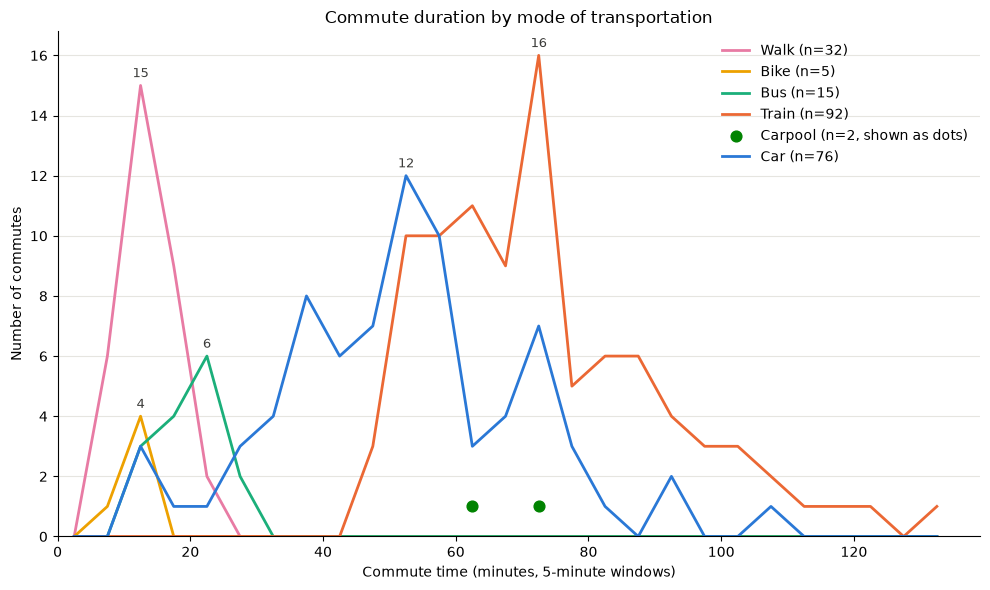

Saved /Users/dj/projects/CS424-Assignment1/figures/task4_commute_duration_by_mode.png


In [1]:
#loading our data and necessary imports
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


root = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent


df = pd.read_csv(root / "data" / "processed" / "commutes_clean.csv")
df["mode_of_transportation"].value_counts()

# color codes + min count for plotting
colors = {
   "Walk": "#e87ba4",
   "Bike": "#eda100",
   "Bus": "#1baf7a",
   "Train": "#eb6834",
   "Carpool": "#008300",
   "Car": "#2a78d6",
}


min_count = 5
bin = 5

bins = np.arange(0, df["duration_minutes"].max() + bin, bin)
centers = bins[:-1] + bin / 2 


fig, ax = plt.subplots(figsize=(10, 6))


for mode, color in colors.items():
   minutes = df.loc[df["mode_of_transportation"] == mode, "duration_minutes"]
   n = len(minutes)
   if n == 0:
       continue


   # count how many commutes fall in each 5-minute window
   counts, _ = np.histogram(minutes, bins=bins)


   if n >= min_count:
       ax.plot(centers, counts, color=color, linewidth=2, label=f"{mode} (n={n})")


       # labeling the maximum with its count
       peak = counts.argmax()
       ax.annotate(f"{counts[peak]}", (centers[peak], counts[peak]),
                   xytext=(0, 6), textcoords="offset points",
                   ha="center", fontsize=9, color="#3a3a38")
   else:
       # Too few for a line: dots only where there are commutes
       has_commutes = counts > 0
       ax.scatter(centers[has_commutes], counts[has_commutes], color=color,
                  s=60, zorder=3, label=f"{mode} (n={n}, shown as dots)")


ax.set_title("Commute duration by mode of transportation")
ax.set_xlabel("Commute time (minutes, 5-minute windows)")
ax.set_ylabel("Number of commutes")
ax.set_xlim(0, None)
ax.set_ylim(0, None)
ax.grid(axis="y", color="#e6e5e0")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)


plt.tight_layout()
plt.show()


graphname = "commute_duration_by_mode"
out = root / "figures" / f"task4_{graphname}.png"
out.parent.mkdir(exist_ok=True)
fig.savefig(out, dpi=200, bbox_inches="tight")
print(f"Saved {out}")
